In [1]:
!pip install umap-learn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

In [3]:
wine = load_wine()

X = wine.data
y = wine.target

feature_names = wine.feature_names

print("Shape:", X.shape)
print("\nFeatures:")
for feature in feature_names:
    print(feature)

Shape: (178, 13)

Features:
alcohol
malic_acid
ash
alcalinity_of_ash
magnesium
total_phenols
flavanoids
nonflavanoid_phenols
proanthocyanins
color_intensity
hue
od280/od315_of_diluted_wines
proline


In [4]:
df = pd.DataFrame(
    X,
    columns=feature_names
)

df["Class"] = y

df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,Class
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [5]:
print(df["Class"].value_counts())

Class
1    71
0    59
2    48
Name: count, dtype: int64


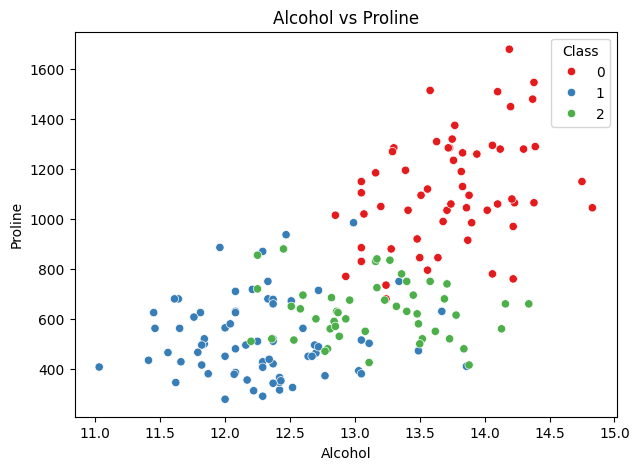

In [6]:
plt.figure(figsize=(7, 5))

sns.scatterplot(
    data=df,
    x="alcohol",
    y="proline",
    hue="Class",
    palette="Set1"
)

plt.title("Alcohol vs Proline")
plt.xlabel("Alcohol")
plt.ylabel("Proline")
plt.show()

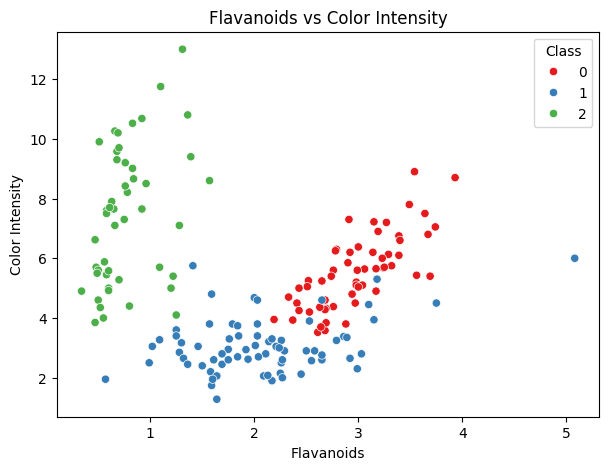

In [7]:
plt.figure(figsize=(7, 5))

sns.scatterplot(
    data=df,
    x="flavanoids",
    y="color_intensity",
    hue="Class",
    palette="Set1"
)

plt.title("Flavanoids vs Color Intensity")
plt.xlabel("Flavanoids")
plt.ylabel("Color Intensity")
plt.show()

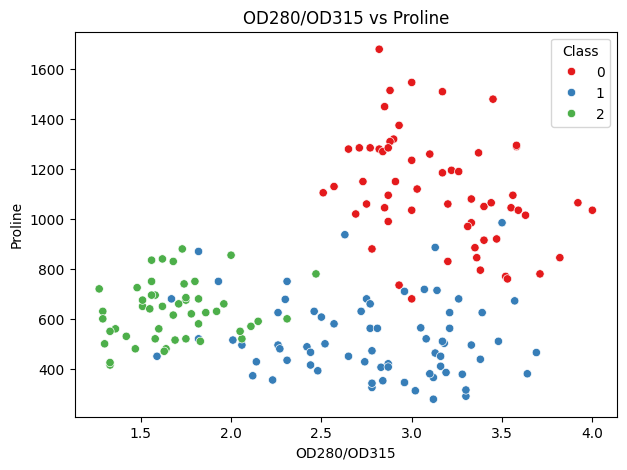

In [8]:
plt.figure(figsize=(7, 5))

sns.scatterplot(
    data=df,
    x="od280/od315_of_diluted_wines",
    y="proline",
    hue="Class",
    palette="Set1"
)

plt.title("OD280/OD315 vs Proline")
plt.xlabel("OD280/OD315")
plt.ylabel("Proline")
plt.show()

Among the three selected feature pairs, the pair that produces the clearest separation is the one with the least overlap between the three classes.

In [9]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Original shape:", X.shape)
print("Scaled shape:", X_scaled.shape)


Original shape: (178, 13)
Scaled shape: (178, 13)


In [10]:
pca = PCA(n_components=2)

pca_result = pca.fit_transform(X_scaled)

print("PCA shape:", pca_result.shape)

PCA shape: (178, 2)


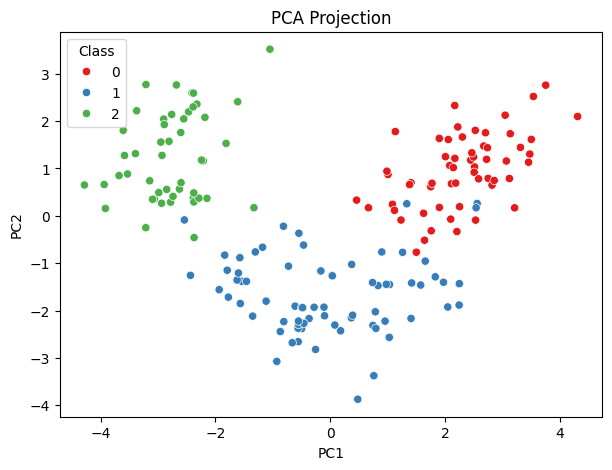

In [11]:
pca_df = pd.DataFrame(
    pca_result,
    columns=["PC1", "PC2"]
)

pca_df["Class"] = y

plt.figure(figsize=(7, 5))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Class",
    palette="Set1"
)

plt.title("PCA Projection")
plt.show()

In [12]:
tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=42
)

tsne_result = tsne.fit_transform(X_scaled)

print("t-SNE shape:", tsne_result.shape)

t-SNE shape: (178, 2)


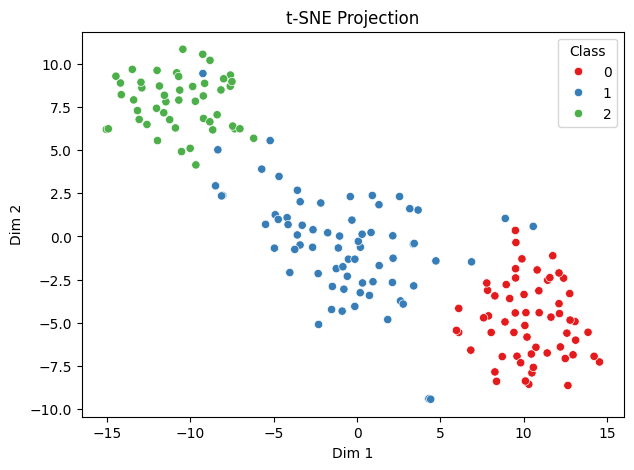

In [13]:
tsne_df = pd.DataFrame(
    tsne_result,
    columns=["Dim 1", "Dim 2"]
)

tsne_df["Class"] = y

plt.figure(figsize=(7, 5))

sns.scatterplot(
    data=tsne_df,
    x="Dim 1",
    y="Dim 2",
    hue="Class",
    palette="Set1"
)

plt.title("t-SNE Projection")
plt.show()

In [14]:
umap_model = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    random_state=42
)

umap_result = umap_model.fit_transform(X_scaled)

print("UMAP shape:", umap_result.shape)

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP shape: (178, 2)


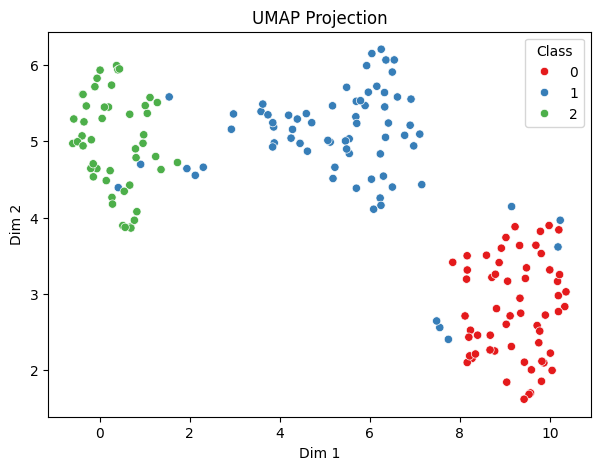

In [15]:
umap_df = pd.DataFrame(
    umap_result,
    columns=["Dim 1", "Dim 2"]
)

umap_df["Class"] = y

plt.figure(figsize=(7, 5))

sns.scatterplot(
    data=umap_df,
    x="Dim 1",
    y="Dim 2",
    hue="Class",
    palette="Set1"
)

plt.title("UMAP Projection")
plt.show()

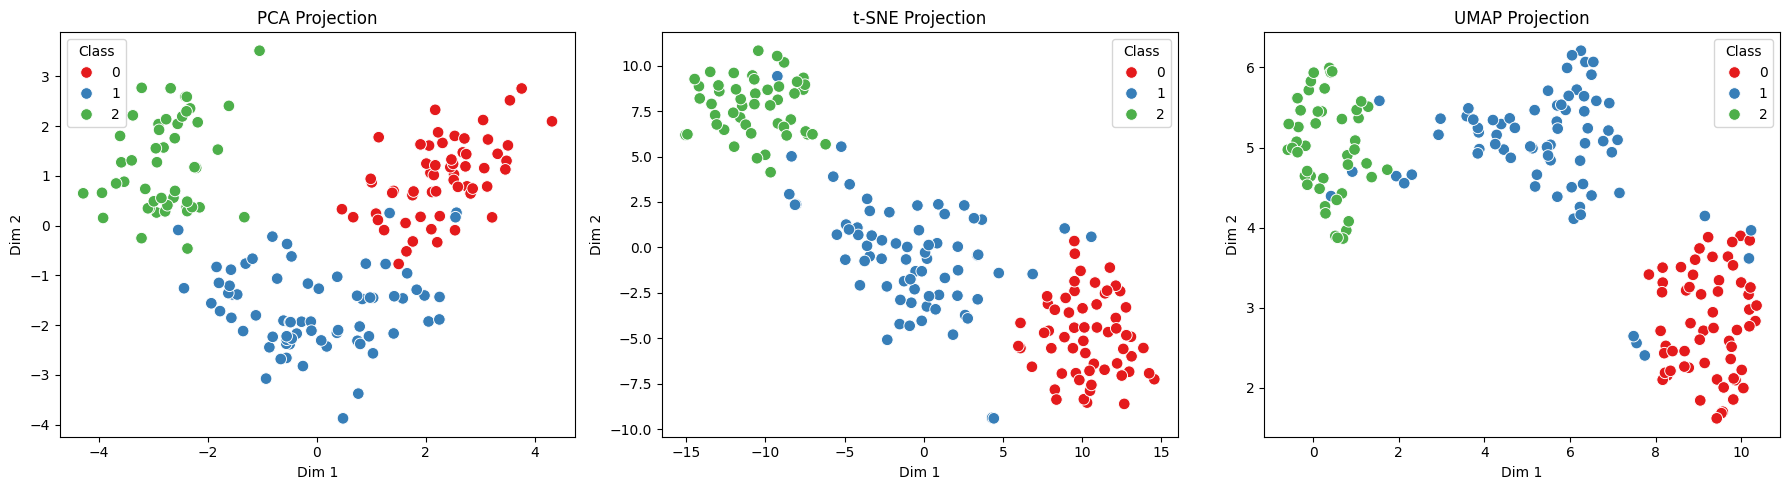

In [16]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5)
)

results = [
    ("PCA", pca_result),
    ("t-SNE", tsne_result),
    ("UMAP", umap_result)
]

for ax, (title, result) in zip(axes, results):

    plot_df = pd.DataFrame(
        result,
        columns=["Dim 1", "Dim 2"]
    )

    plot_df["Class"] = y

    sns.scatterplot(
        data=plot_df,
        x="Dim 1",
        y="Dim 2",
        hue="Class",
        ax=ax,
        s=70,
        palette="Set1"
    )

    ax.set_title(f"{title} Projection")

plt.tight_layout()
plt.show()